# Import and Install Dependencies

In [1]:
pip install opencv-python imageio gdown

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import cv2
import tensorflow as tf
import numpy as np
from typing import List
from matplotlib import pyplot as plt
import imageio

In [3]:
tf.config.list_physical_devices('GPU')#i only have a integrated gpu so no device for gpu

[]

In [4]:
physical_devices = tf.config.list_physical_devices('GPU')
try:
    tf.config.experimental.set_memory_growth(physical_devices[0], True)
except:
    pass # no gpu for me so it will pass

# Building Data Loading functions

In [5]:
import gdown

In [6]:
url = 'https://drive.google.com/uc?id=1YlvpDLix3S-U8fd-gqRwPcWXAXm8JwjL'
output = 'data.zip'
gdown.download(url, output, quiet=False)
gdown.extractall('data.zip')

Downloading...
From (original): https://drive.google.com/uc?id=1YlvpDLix3S-U8fd-gqRwPcWXAXm8JwjL
From (redirected): https://drive.google.com/uc?id=1YlvpDLix3S-U8fd-gqRwPcWXAXm8JwjL&confirm=t&uuid=2996514a-4c69-4e6e-9445-c0b0acf68401
To: c:\Users\shara\OneDrive\Desktop\major\Lip-Reading\data.zip
100%|██████████| 423M/423M [01:59<00:00, 3.54MB/s] 


['data',
 'data\\alignments',
 'data\\alignments\\s1',
 'data\\alignments\\s1\\bbaf2n.align',
 'data\\alignments\\s1\\bbaf3s.align',
 'data\\alignments\\s1\\bbaf4p.align',
 'data\\alignments\\s1\\bbaf5a.align',
 'data\\alignments\\s1\\bbal6n.align',
 'data\\alignments\\s1\\bbal7s.align',
 'data\\alignments\\s1\\bbal8p.align',
 'data\\alignments\\s1\\bbal9a.align',
 'data\\alignments\\s1\\bbas1s.align',
 'data\\alignments\\s1\\bbas2p.align',
 'data\\alignments\\s1\\bbas3a.align',
 'data\\alignments\\s1\\bbaszn.align',
 'data\\alignments\\s1\\bbaz4n.align',
 'data\\alignments\\s1\\bbaz5s.align',
 'data\\alignments\\s1\\bbaz6p.align',
 'data\\alignments\\s1\\bbaz7a.align',
 'data\\alignments\\s1\\bbbf6n.align',
 'data\\alignments\\s1\\bbbf7s.align',
 'data\\alignments\\s1\\bbbf8p.align',
 'data\\alignments\\s1\\bbbf9a.align',
 'data\\alignments\\s1\\bbbm1s.align',
 'data\\alignments\\s1\\bbbm2p.align',
 'data\\alignments\\s1\\bbbm3a.align',
 'data\\alignments\\s1\\bbbmzn.align',
 'data\\a

In [7]:
def load_video(path:str) -> List[float]:
    cap = cv2.VideoCapture(path)
    frames = []

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        if frame is None:
            continue

        try:
            if len(frame.shape) != 3:
                continue

            if frame.shape[0] < 236 or frame.shape[1] < 220:
                continue

            if frame.shape[2] != 3:
                continue

            frame = tf.convert_to_tensor(frame, dtype=tf.uint8)
            frame = tf.image.rgb_to_grayscale(frame)
            frame = frame[190:236,80:220,:]

            if tuple(frame.shape) != (46,140,1):
                continue

            frames.append(frame)

        except Exception:
            continue

    cap.release()

    if not frames:
        raise ValueError(f"No valid frames found in {path}")

    frames = tf.stack(frames)


    frames = tf.cast(frames, tf.float32)
    mean = tf.reduce_mean(frames)
    std = tf.math.reduce_std(frames)
    return (frames - mean) / (std + 1e-8)


In [8]:
vocab = [x for x in "abcdefghijklmnopqrstuvwxyz'?!123456789 "]

In [9]:
char_to_num = tf.keras.layers.StringLookup(vocabulary=vocab, oov_token="")
num_to_char = tf.keras.layers.StringLookup(
    vocabulary=char_to_num.get_vocabulary(), oov_token="", invert=True
)

print(
    f"The vocabulary is: {char_to_num.get_vocabulary()} "
    
    f"(size ={char_to_num.vocabulary_size()})"
)

The vocabulary is: ['', np.str_('a'), np.str_('b'), np.str_('c'), np.str_('d'), np.str_('e'), np.str_('f'), np.str_('g'), np.str_('h'), np.str_('i'), np.str_('j'), np.str_('k'), np.str_('l'), np.str_('m'), np.str_('n'), np.str_('o'), np.str_('p'), np.str_('q'), np.str_('r'), np.str_('s'), np.str_('t'), np.str_('u'), np.str_('v'), np.str_('w'), np.str_('x'), np.str_('y'), np.str_('z'), np.str_("'"), np.str_('?'), np.str_('!'), np.str_('1'), np.str_('2'), np.str_('3'), np.str_('4'), np.str_('5'), np.str_('6'), np.str_('7'), np.str_('8'), np.str_('9'), np.str_(' ')] (size =40)


In [10]:
char_to_num.get_vocabulary()

['',
 np.str_('a'),
 np.str_('b'),
 np.str_('c'),
 np.str_('d'),
 np.str_('e'),
 np.str_('f'),
 np.str_('g'),
 np.str_('h'),
 np.str_('i'),
 np.str_('j'),
 np.str_('k'),
 np.str_('l'),
 np.str_('m'),
 np.str_('n'),
 np.str_('o'),
 np.str_('p'),
 np.str_('q'),
 np.str_('r'),
 np.str_('s'),
 np.str_('t'),
 np.str_('u'),
 np.str_('v'),
 np.str_('w'),
 np.str_('x'),
 np.str_('y'),
 np.str_('z'),
 np.str_("'"),
 np.str_('?'),
 np.str_('!'),
 np.str_('1'),
 np.str_('2'),
 np.str_('3'),
 np.str_('4'),
 np.str_('5'),
 np.str_('6'),
 np.str_('7'),
 np.str_('8'),
 np.str_('9'),
 np.str_(' ')]

In [11]:
#character to numerical value
char_to_num(['h','e','b','l','i','n'])

<tf.Tensor: shape=(6,), dtype=int64, numpy=array([ 8,  5,  2, 12,  9, 14])>

In [12]:
#numerical value to character
num_to_char([8,  5,  2, 12,  9, 14])

<tf.Tensor: shape=(6,), dtype=string, numpy=array([b'h', b'e', b'b', b'l', b'i', b'n'], dtype=object)>

In [13]:
tf.strings.reduce_join([num_to_char([8,  5,  2, 12,  9, 14])])

<tf.Tensor: shape=(), dtype=string, numpy=b'heblin'>

In [14]:
def load_alignments(path:str) -> List[str]:
    with open(path, 'r') as f:
        lines = f.readlines()

    tokens = []
    for line in lines:
        parts = line.split()
        if len(parts) >= 3 and parts[2] != 'sil':
            tokens.extend([' ', parts[2]])

    text = ''.join(tokens)
    chars = list(text)

    return char_to_num(tf.constant(chars))


In [15]:
def load_data(path:str): 
    path = bytes.decode(path.numpy())
    #file_name = path.split('/')[-1].split('.')[0]
    file_name = os.path.splitext(os.path.basename(path))[0]
    video_path = os.path.join('data','s1',f'{file_name}.mpg')
    alignment_path = os.path.join('data','alignments','s1',f'{file_name}.align')
    frames = load_video(video_path) 
    alignments = load_alignments(alignment_path) 
    return frames, alignments

In [16]:
test_path = './data/s1/bbaf2n.mpg'

In [17]:
tf.convert_to_tensor(test_path).numpy().decode('utf-8').split('/')[-1].split('.')[0]

'bbaf2n'

In [18]:
import tensorflow as tf
print(tf.__version__)


2.21.0


In [19]:
frames, alignments = load_data(tf.convert_to_tensor(test_path))

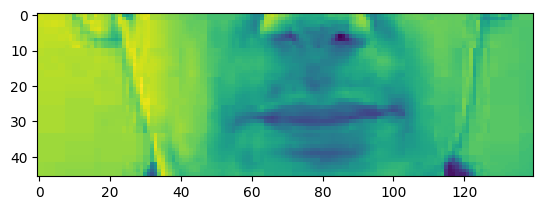

In [20]:
plt.imshow(frames[0])

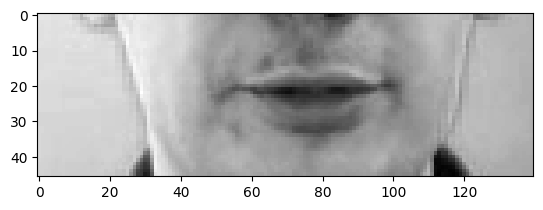

In [21]:
if len(frames) > 40:
    plt.imshow(tf.squeeze(frames[40]), cmap='gray')
    plt.show()
else:
    print("Frame index out of bounds.")

In [22]:
alignments

<tf.Tensor: shape=(21,), dtype=int64, numpy=
array([ 2,  9, 14, 39,  2, 12, 21,  5, 39,  1, 20, 39,  6, 39, 20, 23, 15,
       39, 14, 15, 23])>

In [23]:
tf.strings.reduce_join([bytes.decode(x) for x in num_to_char(alignments.numpy()).numpy()]) 

<tf.Tensor: shape=(), dtype=string, numpy=b'bin blue at f two now'>

In [24]:
def mappable_function(path:str) -> List[str]:
    result = tf.py_function(load_data, [path], (tf.float32, tf.int64))
    return result

# Create Pipeline

In [25]:
data = tf.data.Dataset.list_files('./data/s1/*.mpg')
data = data.shuffle(500, reshuffle_each_iteration=False)
data = data.map(mappable_function)
data = data.padded_batch(2, padded_shapes = ([75, None, None, None], [None]))
data = data.prefetch(tf.data.AUTOTUNE)
train = data.take(450)
test = data.skip(450)

In [26]:
for batch in train.take(1):
    x_batch, y_batch = batch
    print("Shape of x_batch:", x_batch.shape)
    print("Shape of y_batch:", y_batch.shape)


Shape of x_batch: (2, 75, 46, 140, 1)
Shape of y_batch: (2, 40)


In [27]:
len(test)

50

In [28]:
frames, alignments = data.as_numpy_iterator().next()

In [29]:
len(frames)

2

In [30]:
alignments

array([[16, 12,  1,  3,  5, 39,  7, 18,  5,  5, 14, 39,  2, 25, 39, 18,
        39, 20, 23, 15, 39, 16, 12,  5,  1, 19,  5,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0],
       [19,  5, 20, 39,  2, 12, 21,  5, 39, 23,  9, 20,  8, 39, 15, 39,
        20, 23, 15, 39, 16, 12,  5,  1, 19,  5,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0]])

In [31]:
sample = data.as_numpy_iterator()

In [32]:
val = sample.next()
val[0]

array([[[[[ 1.4353796 ],
          [ 1.4353796 ],
          [ 1.3556364 ],
          ...,
          [-0.07974331],
          [ 0.        ],
          [ 0.        ]],

         [[ 1.4353796 ],
          [ 1.4353796 ],
          [ 1.3556364 ],
          ...,
          [-0.07974331],
          [ 0.        ],
          [ 0.        ]],

         [[ 1.275893  ],
          [ 1.275893  ],
          [ 1.275893  ],
          ...,
          [-0.03987166],
          [-0.03987166],
          [-0.03987166]],

         ...,

         [[ 0.9569197 ],
          [ 0.9569197 ],
          [ 0.9569197 ],
          ...,
          [-0.31897324],
          [-0.31897324],
          [-0.31897324]],

         [[ 0.9569197 ],
          [ 0.9569197 ],
          [ 0.9569197 ],
          ...,
          [-0.3588449 ],
          [-0.3588449 ],
          [-0.3588449 ]],

         [[ 0.9569197 ],
          [ 0.9569197 ],
          [ 0.9569197 ],
          ...,
          [-0.3588449 ],
          [-0.3588449 ],
          

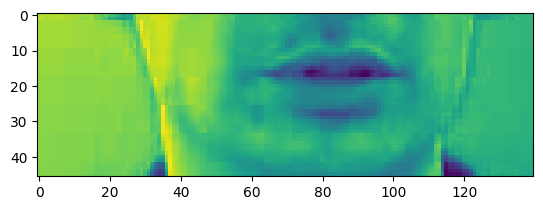

In [33]:
##videos,videos out of batch, return first frame in the video
plt.imshow(val[0][0][0])

In [34]:
tf.strings.reduce_join([num_to_char(word) for word in val[1][0]])

<tf.Tensor: shape=(), dtype=string, numpy=b'place white by k one soon'>

# Design Deep Neural Network

In [35]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv3D, LSTM, Dense, Dropout, Bidirectional, MaxPool3D, Activation, Reshape,Lambda, SpatialDropout3D, BatchNormalization, TimeDistributed, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, LearningRateScheduler
from tensorflow.keras.initializers import Orthogonal 

In [36]:
data.as_numpy_iterator().next()[0][0].shape

(75, 46, 140, 1)

In [37]:
model = Sequential()
model.add(Conv3D(128, 3, input_shape=(75,46,140,1), padding = 'same'))
model.add(Activation('relu'))
model.add(MaxPool3D(pool_size=(1, 2, 2)))

model.add(Conv3D(256, 3, padding = 'same'))
model.add(Activation('relu'))
model.add(MaxPool3D(pool_size=(1, 2, 2)))

model.add(Conv3D(75, 3, padding = 'same'))
model.add(Activation('relu'))
model.add(MaxPool3D(pool_size=(1, 2, 2)))

model.add(TimeDistributed(Flatten()))

model.add(Bidirectional(LSTM(128, kernel_initializer='orthogonal', return_sequences = True)))
model.add(Dropout(0.5))

model.add(Bidirectional(LSTM(128, kernel_initializer='orthogonal', return_sequences = True)))
model.add(Dropout(0.5))

model.add(Dense(char_to_num.vocabulary_size()+ 1, kernel_initializer='he_normal', activation='softmax'))


# Resume from saved checkpoint if available
if os.path.exists('models/checkpoint.weights.h5'):
    model.load_weights('models/checkpoint.weights.h5')
    print('Loaded saved checkpoint weights')


c:\Users\shara\OneDrive\Desktop\major\Lip-Reading\venv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [38]:
46*140*75

483000

In [39]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)                 │ (None, 75, 46, 140,    │         3,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 75, 46, 140,    │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 75, 23, 70,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 75, 23, 70,     │       884,992 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 75, 23, 70,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 75, 11, 35,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 75, 11, 35, 75) │       518,475 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 75, 11, 35, 75) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 75, 5, 17, 75)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 75, 6375)       │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 75, 256)        │     6,660,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 75, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 75, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 75, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 75, 41)         │        10,537 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,471,924 (32.32 MB)

 Trainable params: 8,471,924 (32.32 MB)

 Non-trainable params: 0 (0.00 B)

In [40]:
yhat = model.predict(val[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


In [41]:
#model before train
tf.strings.reduce_join([num_to_char(tf.argmax(x)) for x in yhat[0]])

<tf.Tensor: shape=(), dtype=string, numpy=b'wwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwwfffffff'>

In [42]:
model.input_shape

(None, 75, 46, 140, 1)

In [43]:
model.output_shape

(None, 75, 41)

# Setup Training Options and Train

In [44]:
def scheduler(epochs, lr):
    if epochs < 30:
        return lr
    else:
        return lr*tf.math.exp(-0.1)

In [45]:
def CTCLoss(y_true, y_pred):
    batch_len = tf.cast(tf.shape(y_true)[0], dtype="int64")
    input_length = tf.cast(tf.shape(y_pred)[1], dtype="int64")
    label_length = tf.cast(tf.shape(y_true)[1], dtype="int64")

    input_length = tf.expand_dims(input_length * tf.ones(shape=(batch_len,), dtype='int64'), axis=-1)
    label_length = tf.expand_dims(label_length * tf.ones(shape=(batch_len,), dtype='int64'), axis=-1)

    loss = tf.keras.backend.ctc_batch_cost(y_true, y_pred, input_length, label_length)
    return loss

In [46]:
class ProduceExample(tf.keras.callbacks.Callback):
    def __init__(self, dataset) -> None:
        self.dataset = dataset.as_numpy_iterator()

    def on_epoch_end(self, epoch, logs=None) -> None:
        data = self.dataset.next()
        yhat = self.model.predict(data[0])
        decoded = tf.keras.backend.ctc_decode(yhat, [75,75], greedy=False )[0][0].numpy()
        for x in range(len(yhat)):
            print('Original:', tf.strings.reduce_join(num_to_char(data[1][x])).numpy().decode('utf-8'))
            print('Prediction:', tf.strings.reduce_join(num_to_char(decoded[x])).numpy().decode('utf-8'))
            print('~'*100)

In [47]:
model.compile(optimizer = Adam(learning_rate = 0.0001), loss = CTCLoss)

In [48]:
checkpoint_callback = ModelCheckpoint(os.path.join('models','checkpoint.weights.h5'),monitor = 'loss', save_weights_only = True)

In [49]:
schedule_callback = LearningRateScheduler(scheduler)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

# Stops training once validation loss stops improving, instead of committing to a fixed
# epoch count up front — restores the best weights seen, not just the last epoch's.
early_stopping_callback = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True,
    verbose=1
)

In [50]:
example_callback = ProduceExample(test)

In [ ]:
model.fit(train, validation_data=test, epochs=50, callbacks=[checkpoint_callback, schedule_callback, example_callback, early_stopping_callback])

# Make a Prediction

In [52]:
url = 'https://drive.google.com/uc?id=1vWscXs4Vt0a_1IH1-ct2TCgXAZT-N3_Y'
output = 'checkpoints.zip'
gdown.download(url, output, quiet=False)
gdown.extractall('checkpoints.zip', 'models')

Downloading...
From (original): https://drive.google.com/uc?id=1vWscXs4Vt0a_1IH1-ct2TCgXAZT-N3_Y
From (redirected): https://drive.google.com/uc?id=1vWscXs4Vt0a_1IH1-ct2TCgXAZT-N3_Y&confirm=t&uuid=d5c231d8-939e-4100-94a2-f6ed34de634d
To: c:\Users\shara\OneDrive\Desktop\major\Lip-Reading\checkpoints.zip
100%|██████████| 94.5M/94.5M [00:24<00:00, 3.81MB/s]


['models\\checkpoint.index',
 'models\\__MACOSX\\._checkpoint.index',
 'models\\checkpoint.data-00000-of-00001',
 'models\\__MACOSX\\._checkpoint.data-00000-of-00001',
 'models\\checkpoint',
 'models\\__MACOSX\\._checkpoint']

In [54]:
checkpoint = tf.train.Checkpoint(model=model)
checkpoint.restore('./models/checkpoint').expect_partial()

In [55]:
test_data = test.as_numpy_iterator()


In [56]:
sample = test_data.next()

In [57]:
yhat = model.predict(sample[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


In [58]:
decoded = tf.keras.backend.ctc_decode(yhat, input_length=[75,75], greedy=True)[0][0].numpy()

In [59]:
print('~'*100, 'PREDICTIONS')
[tf.strings.reduce_join([num_to_char(word) for word in sentence]) for sentence in decoded]

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ PREDICTIONS


[<tf.Tensor: shape=(), dtype=string, numpy=b'la o'>,
 <tf.Tensor: shape=(), dtype=string, numpy=b'la o'>]

In [60]:
print('~'*100, 'REAL TEXT')
[tf.strings.reduce_join([num_to_char(word) for word in sentence]) for sentence in sample[1]]

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ REAL TEXT


[<tf.Tensor: shape=(), dtype=string, numpy=b'bin blue at s three again'>,
 <tf.Tensor: shape=(), dtype=string, numpy=b'bin red in z six now'>]

# Test On a Video

In [63]:
sample = load_data(tf.convert_to_tensor('./data/s1/bbaf2n.mpg'))

In [65]:
sample = load_data(tf.convert_to_tensor('./data/s1/bbaf2n.mpg'))
print("Number of frames loaded:", len(sample[0]))


Number of frames loaded: 75


In [66]:
sample = load_data(tf.convert_to_tensor('./data/s1/bras9a.mpg'))

In [67]:
print('~'*100, 'REAL TEXT')
[tf.strings.reduce_join([num_to_char(word) for word in sentence]) for sentence in [sample[1]]]

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ REAL TEXT


[<tf.Tensor: shape=(), dtype=string, numpy=b'bin red at s nine again'>]

In [68]:
sample

(<tf.Tensor: shape=(75, 46, 140, 1), dtype=float32, numpy=
 array([[[[ 1.3833275 ],
          [ 1.3833275 ],
          [ 1.3426414 ],
          ...,
          [ 0.0406861 ],
          [ 0.12205831],
          [ 0.08137221]],
 
         [[ 1.3833275 ],
          [ 1.3833275 ],
          [ 1.3426414 ],
          ...,
          [ 0.08137221],
          [ 0.20343052],
          [ 0.20343052]],
 
         [[ 1.3019553 ],
          [ 1.3019553 ],
          [ 1.3019553 ],
          ...,
          [ 0.        ],
          [ 0.0406861 ],
          [ 0.0406861 ]],
 
         ...,
 
         [[ 0.93578035],
          [ 0.93578035],
          [ 0.93578035],
          ...,
          [-0.28480273],
          [-0.28480273],
          [-0.28480273]],
 
         [[ 0.93578035],
          [ 0.93578035],
          [ 0.93578035],
          ...,
          [-0.28480273],
          [-0.28480273],
          [-0.28480273]],
 
         [[ 0.93578035],
          [ 0.93578035],
          [ 0.93578035],
          

In [69]:
print(sample[0].shape)
print(sample[1].shape)

(75, 46, 140, 1)
(23,)


In [70]:
print(sample[0].shape)
print(sample[1].shape)

(75, 46, 140, 1)
(23,)


In [71]:
sample[0].shape

TensorShape([75, 46, 140, 1])

In [72]:
trimmed_frames = sample[0][:75]
yhat = model.predict(tf.expand_dims(trimmed_frames, axis=0))


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


In [73]:
trimmed_frames = sample[0][:75]
yhat = model.predict(tf.expand_dims(trimmed_frames, axis=0))


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 560ms/step


In [74]:
decoded = tf.keras.backend.ctc_decode(yhat, input_length=[75], greedy=True)[0][0].numpy()

In [75]:
print('~'*100, 'PREDICTIONS')
[tf.strings.reduce_join([num_to_char(word) for word in sentence]) for sentence in decoded]

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ PREDICTIONS


[<tf.Tensor: shape=(), dtype=string, numpy=b'la '>]

print('~'*100, 'REAL TEXT')
[tf.strings.reduce_join([num_to_char(word) for word in sentence]) for sentence in [sample[1]]]

In [76]:
print('~'*100, 'PREDICTIONS')
[tf.strings.reduce_join([num_to_char(word) for word in sentence]) for sentence in decoded]

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ PREDICTIONS


[<tf.Tensor: shape=(), dtype=string, numpy=b'la '>]

In [78]:
print('~'*100, 'REAL TEXT')
[tf.strings.reduce_join([num_to_char(word) for word in sentence]) for sentence in [sample[1]]]

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ REAL TEXT


[<tf.Tensor: shape=(), dtype=string, numpy=b'bin red at s nine again'>]